# Rodízio de assinaturas de streaming
### Quais plataformas assinar em cada mês de 2027 para ver tudo o que eu quero, gastando o mínimo?

**COS360/COM361 – Otimização** · Projeto final · Prof. Luidi Simonetti
**Dupla:** _(Kauã Paiva)_ e _(Giulia Cadorin)_

| | |
|---|---|
| **Problema** | Tenho uma lista de séries e filmes espalhados por 6 plataformas. As assinaturas não têm fidelidade: dá para assinar num mês e cancelar no seguinte. Quais assinar em cada mês? |
| **Modelo** | Programa linear inteiro misto (MILP) que junta **cobertura de conjuntos**, **custo fixo** e **planejamento em vários meses com capacidade** (as minhas horas livres). |
| **Ferramenta** | Python + `scipy.optimize.milp` (solver HiGHS). Só SciPy, NumPy, pandas e Matplotlib. |
| **Dados** | Preços reais de novembro de 2026 e a minha lista para 2027 (fontes na seção 3.4 e nas Referências). |

**Conteúdo da disciplina que aparece aqui**

| Ideia | Onde | Aula |
|---|---|---|
| Programação inteira mista, relaxação linear | modelo inteiro; seção 4.1 | 17–18 |
| Custo fixo e big-M | mensalidade; restrição (4) | 19 |
| Cobertura de conjuntos | cada título precisa de uma assinatura | 21 |
| Planejamento em vários períodos | 12 meses, janelas de disponibilidade | 4–5 |
| Planos de corte, *branch-and-bound* | cortes de Chvátal–Gomory; seção 4.2 | 23 |
| Trade-offs (curvas de compromisso) | custo × tempo livre, custo × espera, custo × anúncios | 9–10 |
| Minimax em PL | divisão justa da conta na república | 4 |

> **Como executar:** *Run All*. O notebook inteiro roda em cerca de 3 a 4 minutos; as análises mais pesadas são as das seções 4.2 e 5.1, que resolvem dezenas de modelos.
> **Para usar os seus dados**, edite só as três tabelas da seção 3.4 (ofertas, lista e horas livres): o resto se adapta.

**Roteiro:** 1. Introdução · 2. Modelo matemático · 3. Solução · 4. Entendendo a solução · 5. Discussão · Referências

## 1. Introdução

### 1.1 O problema do dia a dia
Séries e filmes estão espalhados por várias plataformas: Netflix, HBO Max, Prime Video, Disney+, Apple TV, Globoplay... Em novembro de 2026, assinar **o plano mais barato** de cada uma das sete principais plataformas do Brasil custa **R\$ 205,30 por mês**, ou seja, R\$ 2.463,60 por ano. E só em 2026 o Disney+ (junho), a Apple TV (agosto), a Netflix e o Globoplay (outubro) reajustaram seus preços [ANTI/HYPE, 2026].

Mas há um detalhe: **assinaturas de streaming normalmente não têm fidelidade.** Dá para assinar num mês, maratonar o que interessa, cancelar e voltar meses depois. Esse comportamento ficou tão comum que os relatórios de mercado deram nome a quem o pratica: *serial churners* [Deloitte, 2024]. Aqui chamamos de **rodízio de assinaturas**.

A pergunta deste projeto é:

> **Dada a minha lista do que quero ver em 2027, sabendo em que plataforma e a partir de quando cada título está disponível, e quantas horas livres eu tenho em cada mês, quais assinaturas devo ter em cada mês para ver tudo pagando o mínimo?**

Problemas a se pensar:
- assinar a Netflix em fevereiro e ver tudo dela de uma vez é ótimo... se couber nas horas livres de fevereiro;
- um lançamento só pode ser visto depois da estreia, e um programa ao vivo (como o BBB) só no mês em que passa;
- um combo (como o Meli+ Mega, que junta Netflix, HBO Max, Disney+ e Apple TV) às vezes sai mais barato que as assinaturas separadas, às vezes não;
- um mesmo filme pode estar em duas plataformas ao mesmo tempo.

### 1.2 As plataformas reagem
O rodízio incomoda as plataformas, e várias práticas recentes são respostas a ele:
- **lançamentos semanais** em vez da temporada inteira de uma vez: a série *Harry Potter*, da HBO, estreia em 25/12/2026 com um episódio por semana [Legião dos Heróis, 2026];
- **planos anuais com desconto**;
- **combos**;
- **fim do compartilhamento de senhas entre casas diferentes**: a Netflix cobra "assinante extra".

Na seção 5 usamos o modelo para medir algumas dessas estratégias.

### 1.3 Um pouco de história
O nosso problema combina três problemas clássicos de Pesquisa Operacional:

- **Cobertura de conjuntos (*set covering*).** Entre vários subconjuntos com custo, escolher os mais baratos que cubram todos os elementos. Está na lista dos 21 problemas NP-completos de Karp [Karp, 1972], e a sua heurística gulosa foi analisada por Chvátal [Chvátal, 1979]. Usos clássicos: posicionar serviços de emergência para que todo bairro seja atendido [Toregas et al., 1971] e escalar tripulações de companhias aéreas [Hoffman & Padberg, 1993]. Aqui, os "elementos" são os títulos e os "subconjuntos" são as assinaturas.
- **Custo fixo (*fixed charge*).** Paga-se uma taxa para "ligar" uma opção, não importa o quanto ela seja usada [Hirsch & Dantzig, 1968]. A mensalidade é exatamente isso: o preço é o mesmo vendo 1 hora ou 30.
- **Planejamento em vários períodos com custo de preparação (*lot sizing*).** Decidir em quais períodos "ligar" uma máquina, pagando um custo fixo a cada vez, para atender demandas que surgem ao longo do tempo [Wagner & Whitin, 1958]. Quando a capacidade de cada período é limitada, o problema é NP-difícil [Florian et al., 1980]. É a lógica do exemplo Sailco (aula 5) somada ao custo fixo (aula 19). No nosso caso, a "máquina" é a plataforma e a "capacidade" são as horas livres do mês.

### 1.4 Onde mais isso aparece
A mesma estrutura, "pagar por período para ter acesso a um conjunto de coisas, com capacidade limitada de uso", aparece em:
- empresas escolhendo mês a mês **licenças de software (SaaS)** ou **servidores na nuvem**;
- bibliotecas decidindo quais **bases de periódicos** assinar a cada ano;
- empresas contratando **frete** ou **capacidade de rede** por período;
- e, na versão de um período só, em escalas de tripulação e localização de serviços (cobertura de conjuntos).

## 2. Modelo matemático

### 2.1 A ideia em palavras
Em cada mês decidimos **quais ofertas comprar** (um plano de uma plataforma, com ou sem anúncios, ou um combo) e **quais títulos assistir**. Pagamos a mensalidade de cada oferta comprada. As regras são:
1. cada título da lista é assistido **uma vez**, em algum mês em que está disponível;
2. o que eu assisto em cada mês cabe nas minhas **horas livres** daquele mês;
3. só posso assistir a um título num mês se **comprei, naquele mês, alguma oferta que dá acesso** a uma plataforma onde ele está.

### 2.2 Conjuntos e parâmetros

| Símbolo | Significado |
|---|---|
| $T$ | títulos da minha lista |
| $P$ | plataformas (Netflix, HBO Max, ...) |
| $M=\{1,\dots,12\}$ | meses de 2027 |
| $K$ | ofertas mensais: planos e combos |
| $c_k$ | preço mensal da oferta $k$ (R\$) |
| $P_k \subseteq P$ | plataformas a que a oferta $k$ dá acesso (um plano: 1 plataforma; um combo: várias) |
| $h_t$ | horas para ver o título $t$ inteiro |
| $A_{t,m}\subseteq P$ | plataformas em que $t$ está disponível no mês $m$ (vazio antes da estreia e depois da saída do catálogo) |
| $H_m$ | horas livres no mês $m$ |

Três conjuntos derivados deixam o modelo mais curto:
- $M_t=\{m : A_{t,m}\neq\emptyset\}$: meses em que $t$ pode ser visto (a sua **janela**);
- $K_{t,m}=\{k : P_k\cap A_{t,m}\neq\emptyset\}$: ofertas que dão acesso a $t$ no mês $m$;
- $T_{p,m}=\{t : A_{t,m}=\{p\}\}$: títulos que, no mês $m$, só estão na plataforma $p$.

### 2.3 Variáveis de decisão
$$
y_{k,m}=\begin{cases}1 & \text{se compro a oferta } k \text{ no mês } m\\ 0 & \text{caso contrário}\end{cases}
\qquad\qquad
x_{t,m}=\begin{cases}1 & \text{se assisto ao título } t \text{ no mês } m\\ 0 & \text{caso contrário}\end{cases}\quad (m\in M_t)
$$

### 2.4 O modelo
$$
\begin{aligned}
\min\quad & \sum_{k\in K}\sum_{m\in M} c_k\,y_{k,m} && \text{(custo das mensalidades)}\\[6pt]
\text{s.a.}\quad & \sum_{m\in M_t} x_{t,m} = 1 && \forall\, t\in T \qquad (1)\\
& \sum_{t\in T} h_t\,x_{t,m} \le H_m && \forall\, m\in M \qquad (2)\\
& x_{t,m} \le \sum_{k\in K_{t,m}} y_{k,m} && \forall\, t\in T,\ m\in M_t \qquad (3)\\
& \sum_{t\in T_{p,m}} h_t\,x_{t,m} \le H_m \sum_{k:\,p\in P_k} y_{k,m} && \forall\, p\in P,\ m\in M \qquad (4)\\
& x_{t,m}\in\{0,1\},\quad y_{k,m}\in\{0,1\}
\end{aligned}
$$

| Restrição | Significado |
|---|---|
| (1) | cada título é visto exatamente uma vez, dentro da sua janela |
| (2) | as horas assistidas no mês cabem nas horas livres |
| (3) | só assisto se alguma oferta comprada naquele mês dá acesso ao título (**cobertura**) |
| (4) | **formulação forte**: as horas vistas em títulos exclusivos de $p$ cabem em $H_m$ se $p$ estiver ativa, e são zero se não estiver (seção 4.2) |

### 2.5 De onde vem cada peça

| Peça do modelo | Ideia da disciplina |
|---|---|
| Objetivo só com $y$; os $y$ "ligam" o acesso | **Custo fixo** (aula 19): pago $c_k$ ao fazer $y_{k,m}=1$, vendo 1 hora ou 30. |
| Restrição (3) | **Cobertura de conjuntos** (aula 21): cada título assistido precisa ser "coberto" por uma oferta comprada no mesmo mês. |
| Índice $m$ e restrições (1) e (2) | **Planejamento em vários períodos** (aulas 4–5): a restrição (1) liga os meses entre si. |
| Restrição (4) | **Big-M** (aula 19) com o **menor $M$ válido**, $M=H_m$. Para soluções inteiras ela é redundante (já decorre de (2) e (3)), mas deixa a relaxação linear mais justa (seção 4.2). |

**Por que a restrição (2) é essencial?** Sem limite de horas, o ótimo seria trivial: assinar cada plataforma **um único mês**, depois da sua última estreia, e ver tudo de uma vez. É o limite de horas que obriga a escolher **quais plataformas dividem o mesmo mês** e **quais precisam ser assinadas mais de uma vez**.

### 2.6 Casos especiais que o modelo trata só mudando os dados

| Situação real | Como aparece no modelo |
|---|---|
| Lançamento (só pode ser visto depois da estreia) | $A_{t,m}=\emptyset$ nos meses anteriores à estreia |
| Título que sai do catálogo | $A_{t,m}=\emptyset$ depois da saída |
| Programa ao vivo (o BBB de cada mês) | janela de um mês só: $M_t=\{m\}$ |
| Filme em duas plataformas (*Ainda Estou Aqui*: Globoplay e Netflix) | $A_{t,m}$ com duas plataformas |
| Combo (Meli+ Mega) | oferta $k$ com $P_k$ de várias plataformas |
| Plano com e sem anúncios | duas ofertas diferentes para a mesma plataforma |

### 2.7 Hipóteses e aproximações
1. **Mês fechado:** a assinatura vale do primeiro ao último dia do mês, e cancelar e reassinar é grátis.
2. **Preços constantes em 2027** (os de novembro de 2026), sem promoções.
3. **Horas conhecidas:** $h_t$ é a soma aproximada da duração dos episódios.
4. **Cada título é visto num único mês.** Relaxamos isso na seção 5.1.
5. **Plano com anúncios tem o mesmo catálogo** que o plano sem anúncios; só muda o preço (e o incômodo, medido na seção 3.6).
6. **Datas conhecidas:** as datas de 2027 que ainda não foram confirmadas são estimativas, marcadas na tabela da seção 3.4.
7. **Horas livres $H_m$ são uma estimativa pessoal:** mais nas férias, menos na época de provas.

### 2.8 É difícil?
O problema é **NP-difícil**: com um mês só e $H_m$ enorme, sobram apenas as restrições (3), e o que resta é exatamente uma cobertura de conjuntos. Mas a nossa instância é pequena (algumas centenas de variáveis binárias) e o solver a resolve em segundos com *branch-and-bound* e planos de corte (aula 23).

## 3. Solução

Usamos `scipy.optimize.milp`, que chama o solver de código aberto **HiGHS** [Huangfu & Hall, 2018; Virtanen et al., 2020]. A seção está organizada assim:
- **3.1** bibliotecas e uma camada fina para escrever o modelo "como no papel";
- **3.2** a função que monta o modelo da seção 2.4, e funções para **mostrar** e **conferir** a solução;
- **3.3** um exemplo pequeno, conferido por força bruta;
- **3.4 a 3.6** a instância real de 2027 e a comparação com estratégias simples.

### 3.1 Bibliotecas e camada de modelagem

In [1]:
import itertools
import math
import time
from dataclasses import dataclass
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.sparse import coo_matrix

pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10})

NOMES_MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
F = frozenset   # atalho: conjunto imutável de plataformas


def brl(valor):
    """Formata como dinheiro brasileiro: 1234.5 -> 'R$ 1.234,50'."""
    return "R$ " + f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [2]:
class ModeloMILP:
    """
    Camada fina sobre scipy.optimize.milp.

    O milp recebe o problema na forma matricial
        min c^T z   s.a.   lo <= A z <= hi,   0 <= z <= u,   z_i inteiro para i em I.
    Montar a matriz A à mão é trabalhoso e pouco legível. Esta classe deixa escrever o
    modelo "como no papel": criamos variáveis com nome e adicionamos restrições como
    somas de termos (coeficiente, variável). No final ela monta c, A, lo, hi e chama o solver.
    """

    def __init__(self):
        self.nomes, self.custos, self.limites_sup, self.eh_inteira = [], [], [], []
        self.restricoes = []                      # lista de (termos, mínimo, máximo)

    def variavel(self, nome, custo=0.0, inteira=True, lim_sup=1.0):
        """Cria a variável 0 <= z <= lim_sup (inteira ou contínua) e devolve o seu índice."""
        self.nomes.append(nome)
        self.custos.append(custo)
        self.limites_sup.append(lim_sup)
        self.eh_inteira.append(inteira)
        return len(self.nomes) - 1

    def restricao(self, termos, minimo=-np.inf, maximo=np.inf):
        """Adiciona  minimo <= soma(coef * z[var]) <= maximo,  com termos = [(coef, var), ...]."""
        self.restricoes.append(([(c, v) for c, v in termos if c != 0], minimo, maximo))

    def resolver(self, relaxar=False, limite_tempo=60):
        """Monta as matrizes e chama o HiGHS. relaxar=True resolve a relaxação linear."""
        n, r = len(self.nomes), len(self.restricoes)
        lin, col, val = [], [], []
        for i, (termos, _, _) in enumerate(self.restricoes):
            for c, v in termos:
                lin.append(i); col.append(v); val.append(c)
        A = coo_matrix((val, (lin, col)), shape=(r, n)).tocsr()   # matriz esparsa
        lo = np.array([mn for _, mn, _ in self.restricoes], dtype=float)
        hi = np.array([mx for _, _, mx in self.restricoes], dtype=float)
        inteiras = np.zeros(n) if relaxar else np.array(self.eh_inteira, dtype=float)
        inicio = time.perf_counter()
        res = milp(c=np.array(self.custos), constraints=LinearConstraint(A, lo, hi),
                   bounds=Bounds(np.zeros(n), np.array(self.limites_sup)),
                   integrality=inteiras, options={"time_limit": limite_tempo})
        res.tempo = time.perf_counter() - inicio
        res.tamanho = {"variáveis": n, "binárias": int(inteiras.sum()), "restrições": r}
        return res

### 3.2 O modelo em código
A função `otimizar` monta **exatamente** o modelo da seção 2.4, e cada bloco do código traz o número da restrição correspondente. Os parâmetros extras (`relaxar`, `forte`, `cortes`, `dividir`, `espera_max`, `ofertas_anuais` e várias pessoas) servem para as análises das seções 4 e 5 e, desligados, não mudam o modelo básico.

**Formato dos dados.** A lista de títulos é uma tabela com **uma linha por título e plataforma**: um título disponível em duas plataformas ocupa duas linhas, cada uma com a sua janela (`de`, `ate`, em meses de 1 a 12). É assim que construímos os conjuntos $A_{t,m}$.

In [3]:
def processar_entrada(lista, horas, espera_max=None):
    """
    Converte a tabela 'lista' nos conjuntos do modelo (seção 2.2).

    lista : DataFrame com colunas titulo, plataforma, de, ate, horas
            (opcionais: sem_spoiler, quem). Um título em duas plataformas ocupa duas linhas.
    horas : {mês: H_m}, que vale para todos, ou {pessoa: {mês: H_m}} (seção 5.4)
    espera_max : se não for None, títulos com sem_spoiler=True só podem ser vistos até
                 'espera_max' meses depois da estreia (seção 5.2)
    """
    lista = lista.copy()
    if "quem" not in lista:
        lista["quem"] = "Eu"
    if "sem_spoiler" not in lista:
        lista["sem_spoiler"] = False
    pessoas = list(dict.fromkeys(lista["quem"]))
    if all(isinstance(v, dict) for v in horas.values()):
        H = {p: dict(horas[p]) for p in pessoas}
    else:
        H = {p: dict(horas) for p in pessoas}
    meses = sorted(H[pessoas[0]])

    unidades, info = [], {}            # unidade = (título, pessoa que vai assistir)
    for (titulo, pessoa), linhas in lista.groupby(["titulo", "quem"], sort=False):
        duracao = linhas["horas"].unique()
        if len(duracao) != 1:
            raise ValueError(f"'{titulo}' aparece com durações diferentes em linhas diferentes")
        # A[m] = plataformas em que o título está disponível no mês m  (conjunto A_{t,m})
        A = {m: F(linhas.loc[(linhas["de"] <= m) & (linhas["ate"] >= m), "plataforma"]) for m in meses}
        estreia = min((m for m in meses if A[m]), default=None)
        if estreia is None:
            raise ValueError(f"'{titulo}' não está disponível em nenhum mês do horizonte")
        if espera_max is not None and linhas["sem_spoiler"].any():
            A = {m: (A[m] if m <= estreia + espera_max else F()) for m in meses}
        unidades.append((titulo, pessoa))
        info[(titulo, pessoa)] = {"horas": float(duracao[0]), "A": A, "estreia": estreia,
                                  "plataformas": F(linhas["plataforma"])}
    return {"pessoas": pessoas, "H": H, "meses": meses, "unidades": unidades, "info": info,
            "plataformas": list(dict.fromkeys(lista["plataforma"]))}


@dataclass
class Plano:
    """Resultado de uma otimização: as decisões e tudo o que é preciso para mostrá-las e conferi-las."""
    custo: float              # valor da função objetivo (R$)
    status: str               # "ótimo" ou "limite de tempo" (melhor plano achado até ali)
    limite_inferior: float    # melhor limite inferior provado pelo solver
    tempo: float              # segundos
    tamanho: dict             # número de variáveis e de restrições
    y: pd.DataFrame           # y[oferta, mês]: 0/1 (ou fração, na relaxação linear)
    anuais: list              # ofertas anuais compradas (seção 5.3)
    x: dict                   # x[(título, pessoa)] = {mês: fração assistida}
    dados: dict               # entradas já processadas

    @property
    def otimo(self):
        return self.status == "ótimo"


STATUS = {0: "ótimo", 1: "limite de tempo", 2: "inviável", 3: "ilimitado", 4: "erro numérico"}


def otimizar(lista, ofertas, horas, *, ofertas_anuais=None, relaxar=False, forte=True, cortes=True,
             dividir=False, espera_max=None, limite_tempo=60):
    """
    Monta e resolve o modelo da seção 2.4. Devolve um Plano, ou None se o problema for inviável.

    ofertas        : DataFrame com colunas oferta, plataformas (frozenset), preco
    ofertas_anuais : (seção 5.3) ofertas pagas uma vez que valem os 12 meses
    relaxar        : (seção 4.1) relaxação linear: todas as variáveis contínuas em [0, 1]
    forte, cortes  : (seção 4.2) liga a restrição (4) e os cortes (5)
    dividir        : (seção 5.1) permite ver um título em partes, em meses diferentes
    espera_max     : (seção 5.2) espera máxima, em meses, para títulos marcados sem_spoiler
    """
    d = processar_entrada(lista, horas, espera_max)
    meses, info, H = d["meses"], d["info"], d["H"]
    ofertas = ofertas.reset_index(drop=True)
    anuais = (ofertas_anuais if ofertas_anuais is not None else ofertas.iloc[0:0]).reset_index(drop=True)
    d["ofertas"], d["anuais"] = ofertas, anuais
    mod = ModeloMILP()

    # ---------------- variáveis ----------------
    # y[k, m] = 1 se compro a oferta k no mês m; o preço c_k vai para a função objetivo
    y = {(k, m): mod.variavel(f"y[{k},{m}]", custo=ofertas.at[k, "preco"])
         for k in ofertas.index for m in meses}
    # z[j] = 1 se compro a oferta anual j (só na seção 5.3)
    z = {j: mod.variavel(f"z[{j}]", custo=anuais.at[j, "preco"]) for j in anuais.index}
    # x[u, m] = 1 se assisto u = (título, pessoa) no mês m; só existe dentro da janela M_t
    x = {(u, m): mod.variavel(f"x[{u},{m}]", inteira=not dividir)
         for u in d["unidades"] for m in meses if info[u]["A"][m]}

    def acesso(plataformas):
        """Ofertas (mensais e anuais) que dão acesso a pelo menos uma dessas plataformas."""
        ks = [k for k in ofertas.index if ofertas.at[k, "plataformas"] & plataformas]
        js = [j for j in anuais.index if anuais.at[j, "plataformas"] & plataformas]
        return ks, js

    # (1) cada título é visto exatamente uma vez, dentro da sua janela
    for u in d["unidades"]:
        mod.restricao([(1, x[u, m]) for m in meses if (u, m) in x], minimo=1, maximo=1)

    # (2) horas livres: o que cada pessoa assiste no mês cabe em H_m
    for p in d["pessoas"]:
        for m in meses:
            mod.restricao([(info[u]["horas"], x[u, m]) for u in d["unidades"]
                           if u[1] == p and (u, m) in x], maximo=H[p][m])

    # (3) cobertura: x[t, m] <= soma das ofertas compradas no mês m que dão acesso a t
    for (u, m), xv in x.items():
        ks, js = acesso(info[u]["A"][m])
        mod.restricao([(1, xv)] + [(-1, y[k, m]) for k in ks] + [(-1, z[j]) for j in js], maximo=0)

    # (4) formulação forte (big-M com M = H_m): horas em títulos que, no mês m, só estão
    #     na plataforma pl  <=  H_m * (ofertas compradas que dão acesso a pl)
    if forte:
        for p in d["pessoas"]:
            for pl in d["plataformas"]:
                ks, js = acesso({pl})
                for m in meses:
                    so_em_pl = [u for u in d["unidades"] if u[1] == p and info[u]["A"][m] == {pl}]
                    if so_em_pl:
                        mod.restricao([(info[u]["horas"], x[u, m]) for u in so_em_pl]
                                      + [(-H[p][m], y[k, m]) for k in ks]
                                      + [(-H[p][m], z[j]) for j in js], maximo=0)

    # (5) cortes de Chvátal-Gomory (seção 4.2): a plataforma pl precisa estar ativa em pelo
    #     menos ceil(h_pl / H_max) meses, em que h_pl = horas dos títulos que só existem em pl
    if cortes:
        for pl in d["plataformas"]:
            ks, js = acesso({pl})
            minimo = max(math.ceil(sum(info[u]["horas"] for u in d["unidades"]
                                       if u[1] == p and info[u]["plataformas"] == {pl})
                                   / max(H[p].values()) - 1e-9)
                         for p in d["pessoas"])
            if minimo > 0:
                mod.restricao([(1, y[k, m]) for k in ks for m in meses]
                              + [(len(meses), z[j]) for j in js], minimo=minimo)

    # ---------------- resolve e organiza a resposta ----------------
    res = mod.resolver(relaxar=relaxar, limite_tempo=limite_tempo)
    if res.x is None:                       # inviável (ou nenhum plano achado dentro do tempo)
        return None
    s = res.x
    tabela_y = pd.DataFrame([[s[y[k, m]] for m in meses] for k in ofertas.index],
                            index=ofertas["oferta"], columns=meses)
    assistido = {u: {m: s[x[u, m]] for m in meses if (u, m) in x and s[x[u, m]] > 1e-6}
                 for u in d["unidades"]}
    limite = getattr(res, "mip_dual_bound", None)
    return Plano(custo=res.fun, status=STATUS.get(res.status, str(res.status)),
                 limite_inferior=res.fun if (relaxar or limite is None) else limite,
                 tempo=res.tempo, tamanho=res.tamanho, y=tabela_y,
                 anuais=[anuais.at[j, "oferta"] for j in anuais.index if s[z[j]] > 0.5],
                 x=assistido, dados=d)

A seguir, as funções para **ver** e **conferir** o resultado. A função `verificar` não usa nada do solver: ela refaz todas as contas a partir das decisões (cada título visto uma vez, horas, acesso e custo). Se o modelo tivesse algum erro, por exemplo uma restrição esquecida, o plano passaria no solver e seria reprovado aqui.

In [4]:
def verificar(plano, tol=1e-6):
    """Confere o plano SEM o solver. Devolve a lista de problemas (lista vazia = plano válido)."""
    d = plano.dados
    ofertas, anuais = d["ofertas"], d["anuais"]
    acesso_anual = F().union(*[anuais.loc[anuais["oferta"] == a, "plataformas"].iat[0] for a in plano.anuais])
    problemas = []
    for u in d["unidades"]:
        if abs(sum(plano.x[u].values()) - 1) > tol:
            problemas.append(f"{u[0]} ({u[1]}) não foi visto exatamente uma vez")
        for m, f in plano.x[u].items():
            A = d["info"][u]["A"][m]
            acesso_mes = F().union(*[ofertas.at[k, "plataformas"] for k in ofertas.index
                                     if plano.y.iat[k, d["meses"].index(m)] > 0.5]) | acesso_anual
            if not A:
                problemas.append(f"{u[0]} visto em {NOMES_MESES[m - 1]}, fora da janela")
            elif not (A & acesso_mes):
                problemas.append(f"{u[0]} visto em {NOMES_MESES[m - 1]} sem assinatura que dê acesso")
    for p in d["pessoas"]:
        for m in d["meses"]:
            uso = sum(d["info"][u]["horas"] * plano.x[u].get(m, 0) for u in d["unidades"] if u[1] == p)
            if uso > d["H"][p][m] + tol:
                problemas.append(f"{p} usa {uso:.1f} h em {NOMES_MESES[m - 1]}, mais que {d['H'][p][m]} h livres")
    custo = (plano.y.values.round() * ofertas["preco"].values[:, None]).sum()
    custo += sum(anuais.loc[anuais["oferta"] == a, "preco"].iat[0] for a in plano.anuais)
    if abs(custo - plano.custo) > 1e-4:
        problemas.append(f"custo recalculado {brl(custo)} difere do custo do solver {brl(plano.custo)}")
    return problemas


def gasto_mensal(plano):
    """Lista com quanto se paga em cada mês (sem as ofertas anuais)."""
    precos = plano.dados["ofertas"]["preco"].values
    return [(plano.y.iloc[:, j].values.round() * precos).sum() for j in range(len(plano.dados["meses"]))]


def tabela_plano(plano):
    """Tabela mês a mês: o que assinar, quanto custa, o que assistir e as horas usadas."""
    d = plano.dados
    varias = len(d["pessoas"]) > 1
    gastos = gasto_mensal(plano)
    linhas = []
    for j, m in enumerate(d["meses"]):
        compradas = [o for o in plano.y.index if plano.y.at[o, m] > 0.5]
        vistos = [(u, f) for u in d["unidades"] for mm, f in plano.x[u].items() if mm == m]
        nomes = [u[0] + (f" ({u[1]})" if varias else "") + (f" [{f:.0%}]" if f < 0.999 else "")
                 for u, f in vistos]
        uso = sum(d["info"][u]["horas"] * f for u, f in vistos)
        livre = sum(d["H"][p][m] for p in d["pessoas"])
        linhas.append({"mês": NOMES_MESES[m - 1],
                       "assinar": " + ".join(compradas) if compradas else "—",
                       "custo": brl(gastos[j]) if compradas else "—",
                       "assistir": ", ".join(nomes) if nomes else "—",
                       "horas usadas / livres": f"{uso:.0f} / {livre:.0f}"})
    if plano.anuais:
        anuais = d["anuais"].set_index("oferta")["preco"]
        linhas.append({"mês": "ano todo", "assinar": " + ".join(plano.anuais),
                       "custo": brl(sum(anuais[a] for a in plano.anuais)), "assistir": "",
                       "horas usadas / livres": ""})
    return pd.DataFrame(linhas).set_index("mês")


CORES = ["#eef1f5", "#2f6db5", "#e59f3a", "#4c9a6a"]   # sem acesso | plano | combo | anual


def calendario(plano, titulo="Plano"):
    """Figura do plano: gasto por mês (em cima) e acesso a cada plataforma (embaixo)."""
    d = plano.dados
    meses, plats, ofertas, anuais = d["meses"], d["plataformas"], d["ofertas"], d["anuais"]
    P, M = len(plats), len(meses)
    estado = np.zeros((P, M), dtype=int)           # 0 sem acesso, 1 plano, 2 combo, 3 anual
    for j in range(M):
        for k in ofertas.index:
            if plano.y.iat[k, j] > 0.5:
                tipo = 2 if len(ofertas.at[k, "plataformas"]) > 1 else 1
                for pl in ofertas.at[k, "plataformas"] & set(plats):
                    i = plats.index(pl)
                    estado[i, j] = tipo if estado[i, j] == 0 else min(estado[i, j], tipo)
        for a in plano.anuais:
            for pl in anuais.loc[anuais["oferta"] == a, "plataformas"].iat[0] & set(plats):
                if estado[plats.index(pl), j] == 0:
                    estado[plats.index(pl), j] = 3
    horas = np.zeros((P, M))
    for u, por_mes in plano.x.items():
        for m, f in por_mes.items():
            j = meses.index(m)
            onde = [pl for pl in plats if pl in d["info"][u]["A"][m] and estado[plats.index(pl), j] > 0]
            if onde:
                horas[plats.index(onde[0]), j] += d["info"][u]["horas"] * f
    gastos = gasto_mensal(plano)
    uso = horas.sum(axis=0)
    livre = [sum(d["H"][p][m] for p in d["pessoas"]) for m in meses]
    total_anual = sum(anuais.loc[anuais["oferta"] == a, "preco"].iat[0] for a in plano.anuais)

    fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(max(7.5, 1.2 + 0.85 * M), 2.3 + 0.45 * P), sharex=True,
                                   gridspec_kw={"height_ratios": [1.3, 0.45 * P]})
    ax0.bar(range(M), gastos, color="#5b6b82", width=0.62)
    for j, g in enumerate(gastos):
        if g > 0:
            ax0.text(j, g, f"{g:.2f}".replace(".", ","), ha="center", va="bottom", fontsize=8)
    ax0.set_yticks([]); ax0.spines["left"].set_visible(False)
    ax0.set_ylim(0, max(gastos + [1]) * 1.3)
    extra = f" (inclui {brl(total_anual)} de planos anuais)" if total_anual else ""
    periodo = "no ano" if M == 12 else f"em {M} meses"
    ax0.set_title(f"{titulo}: {brl(sum(gastos) + total_anual)} {periodo}{extra}", loc="left")
    ax0.set_ylabel("R$ no mês", fontsize=9)

    ax1.imshow(estado, cmap=ListedColormap(CORES), vmin=-0.5, vmax=3.5, aspect="auto")
    for i in range(P):
        for j in range(M):
            if horas[i, j] > 1e-6:
                ax1.text(j, i, f"{horas[i, j]:.0f}h", ha="center", va="center", fontsize=8.5,
                         fontweight="bold", color="white" if estado[i, j] in (1, 3) else "black")
    ax1.set_yticks(range(P)); ax1.set_yticklabels(plats)
    ax1.set_xticks(range(M))
    ax1.set_xticklabels([f"{NOMES_MESES[m - 1]}\n{uso[j]:.0f}/{livre[j]:.0f}h" for j, m in enumerate(meses)],
                        fontsize=8.5)
    ax1.set_xticks(np.arange(-0.5, M), minor=True); ax1.set_yticks(np.arange(-0.5, P), minor=True)
    ax1.grid(which="minor", color="white", linewidth=2); ax1.tick_params(which="minor", length=0)
    for s in ax1.spines.values():
        s.set_visible(False)
    rotulos = {1: "plano da plataforma", 2: "via combo", 3: "via plano anual"}
    legenda = [Patch(color=CORES[t], label=r) for t, r in rotulos.items() if (estado == t).any()]
    ax1.legend(handles=legenda, loc="upper left", bbox_to_anchor=(0, -0.27), ncol=3, frameon=False, fontsize=8.5)
    fig.text(0.99, 0.01, "número na célula = horas assistidas ali  ·  abaixo do mês = horas usadas / livres",
             ha="right", fontsize=8, color="#555")
    plt.tight_layout()
    plt.show()

### 3.3 Exemplo pequeno (dá para conferir à mão)
Antes da instância real, um caso de brinquedo: **3 plataformas, 6 títulos, 3 meses e 20 horas livres por mês**. Os títulos são genéricos para facilitar a conta; os preços são os reais.

In [5]:
ofertas_peq = pd.DataFrame([
    ("Netflix Padrão c/ anúncios", F({"Netflix"}),     25.90),
    ("HBO Max Básico c/ anúncios", F({"HBO Max"}),     29.90),
    ("Amazon Prime (Prime Video)", F({"Prime Video"}), 19.90),
], columns=["oferta", "plataformas", "preco"])

lista_peq = pd.DataFrame([
    # título,     plataforma,   de, até, horas
    ("Série N1", "Netflix",      1, 3, 10),
    ("Série N2", "Netflix",      2, 3,  6),     # estreia em fevereiro
    ("Série H1", "HBO Max",      1, 3,  8),
    ("Série H2", "HBO Max",      2, 3, 10),     # estreia em fevereiro
    ("Série P1", "Prime Video",  1, 3,  8),
    ("Série P2", "Prime Video",  3, 3,  8),     # estreia em março
], columns=["titulo", "plataforma", "de", "ate", "horas"])
horas_peq = {1: 20, 2: 20, 3: 20}

display(lista_peq)
print(f"Total: {lista_peq['horas'].sum()} h para ver  |  {sum(horas_peq.values())} h livres nos 3 meses")

,titulo,plataforma,de,ate,horas
0,Série N1,Netflix,1,3,10
1,Série N2,Netflix,2,3,6
2,Série H1,HBO Max,1,3,8
3,Série H2,HBO Max,2,3,10
4,Série P1,Prime Video,1,3,8
5,Série P2,Prime Video,3,3,8


Total: 50 h para ver  |  60 h livres nos 3 meses


Custo mínimo: R$ 121,50  (ótimo)
Conferência independente: OK


,assinar,custo,assistir,horas usadas / livres
mês,,,,
jan,Netflix Padrão c/ anúncios + Amazon Prime (Prime Video),"R$ 45,80","Série N1, Série P1",18 / 20
fev,HBO Max Básico c/ anúncios,"R$ 29,90","Série H1, Série H2",18 / 20
mar,Netflix Padrão c/ anúncios + Amazon Prime (Prime Video),"R$ 45,80","Série N2, Série P2",14 / 20


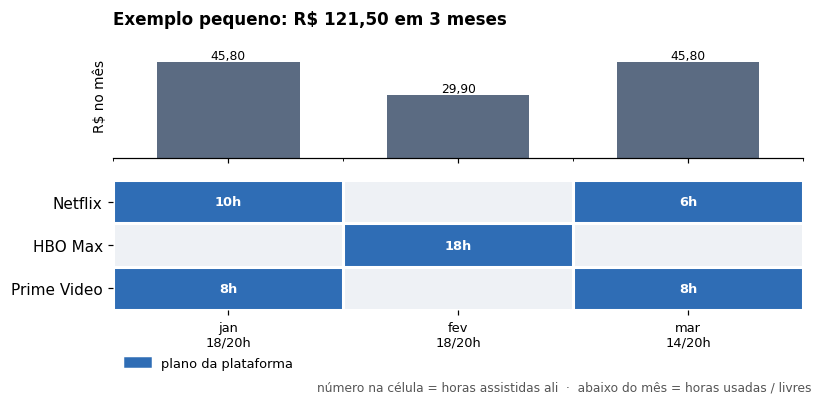

In [6]:
plano_peq = otimizar(lista_peq, ofertas_peq, horas_peq)
print(f"Custo mínimo: {brl(plano_peq.custo)}  ({plano_peq.status})")
print("Conferência independente:", verificar(plano_peq) or "OK")
display(tabela_plano(plano_peq))
calendario(plano_peq, "Exemplo pequeno")

**Por que não dá para pagar só 3 mensalidades, uma por plataforma?** A série P2 só existe em março, então o Prime Video precisa estar ativo em março, e as duas séries dele ocupam 16 das 20 horas daquele mês. A Netflix (16 h) e a HBO Max (18 h) têm séries que só estreiam em fevereiro, então cada uma precisaria caber inteira em fevereiro ou em março. Não cabem as duas em fevereiro (34 h) e nenhuma delas cabe em março, que só tem 4 h sobrando. Com 4 mensalidades também não dá (o mesmo raciocínio vale para qualquer plataforma que se repita), então o mínimo são 5. O modelo escolheu repetir as duas mais baratas que resolvem o problema.

**Conferência por força bruta.** Como são poucos títulos, dá para testar **todas** as formas de escolher o mês de cada título e, para cada uma, pagar a combinação de ofertas mais barata de cada mês. Isso não usa o modelo, então é uma verificação independente:

In [7]:
def cobertura_mais_barata(ofertas):
    """
    Devolve f(exigencias) = (custo, ofertas) da combinação mais barata de ofertas que atende
    todas as exigências. Cada exigência é um conjunto de plataformas e é atendida se a
    combinação der acesso a pelo menos uma delas. Força bruta: há poucas ofertas.
    """
    opcoes = list(zip(ofertas["oferta"], ofertas["plataformas"], ofertas["preco"]))

    @lru_cache(maxsize=None)
    def f(exigencias):
        if not exigencias:
            return 0.0, ()
        uteis = [o for o in opcoes if any(o[1] & e for e in exigencias)]
        melhor = (math.inf, ())
        for r in range(1, len(uteis) + 1):
            for comb in itertools.combinations(uteis, r):
                custo = sum(o[2] for o in comb)
                acesso = F().union(*(o[1] for o in comb))
                if custo < melhor[0] - 1e-9 and all(acesso & e for e in exigencias):
                    melhor = (custo, tuple(o[0] for o in comb))
        return melhor
    return f


def forca_bruta(lista, ofertas, horas):
    """Testa todas as atribuições título -> mês (dentro das janelas e das horas livres)."""
    d = processar_entrada(lista, horas)
    cobrir = cobertura_mais_barata(ofertas)
    janelas = [[m for m in d["meses"] if d["info"][u]["A"][m]] for u in d["unidades"]]
    melhor, testadas = (math.inf, None), 0
    for escolha in itertools.product(*janelas):
        testadas += 1
        uso = {m: 0.0 for m in d["meses"]}
        for u, m in zip(d["unidades"], escolha):
            uso[m] += d["info"][u]["horas"]
        if any(uso[m] > d["H"]["Eu"][m] + 1e-9 for m in d["meses"]):
            continue
        custo = sum(cobrir(F(d["info"][u]["A"][m] for u, mm in zip(d["unidades"], escolha) if mm == m))[0]
                    for m in d["meses"])
        if custo < melhor[0] - 1e-9:
            melhor = (custo, escolha)
    return melhor[0], testadas


custo_fb, testadas = forca_bruta(lista_peq, ofertas_peq, horas_peq)
print(f"Força bruta ({testadas} atribuições testadas): {brl(custo_fb)}")
print(f"MILP:                                   {brl(plano_peq.custo)}")
assert abs(custo_fb - plano_peq.custo) < 1e-6, "O MILP e a força bruta deveriam coincidir!"
print("✔ Os dois coincidem.")
tudo_peq = ofertas_peq["preco"].sum() * len(horas_peq)
print(f"\nAssinar as 3 plataformas nos 3 meses custaria {brl(tudo_peq)}: "
      f"o plano ótimo economiza {1 - plano_peq.custo / tudo_peq:.0%}.")

Força bruta (108 atribuições testadas): R$ 121,50
MILP:                                   R$ 121,50
✔ Os dois coincidem.

Assinar as 3 plataformas nos 3 meses custaria R$ 227,10: o plano ótimo economiza 46%.


### 3.4 Dados reais: preços de novembro de 2026 e a minha lista para 2027

**Ofertas.** Preços mensais consultados em 18/11/2026. Para cada plataforma há o plano mais barato com anúncios e o plano sem anúncios (a Apple TV só tem um plano, sem anúncios), além dos dois níveis do combo Meli+ Mega, do Mercado Livre.

| Oferta | Fonte (data) |
|---|---|
| Netflix, HBO Max, Prime Video, Disney+, Globoplay, Apple TV | ANTI/HYPE (09/11/2026), conferido com Oficina da Net (20/10/2026) |
| Meli+ Mega: com anúncios (R\$ 74,90) e sem anúncios (R\$ 149,90) | Canaltech (21/05/2026). **Conferir o preço atual no app do Mercado Livre.** |

> Preços mudam com frequência. Se algum mudar, basta editar a tabela abaixo e rodar tudo de novo.

In [8]:
# Ofertas mensais (planos e combos). preço em R$/mês; anuncios = a oferta inclui plano com anúncios
ofertas = pd.DataFrame([
    # oferta,                                   dá acesso a,                                       R$/mês, anúncios?
    ("Netflix Padrão c/ anúncios",               F({"Netflix"}),                                    25.90, True),
    ("Netflix Padrão",                           F({"Netflix"}),                                    51.90, False),
    ("HBO Max Básico c/ anúncios",               F({"HBO Max"}),                                    29.90, True),
    ("HBO Max Standard",                         F({"HBO Max"}),                                    44.90, False),
    ("Amazon Prime (Prime Video c/ anúncios)",   F({"Prime Video"}),                                19.90, True),
    ("Amazon Prime + Prime Video sem anúncios",  F({"Prime Video"}),                                29.90, False),
    ("Disney+ Padrão c/ anúncios",               F({"Disney+"}),                                    29.90, True),
    ("Disney+ Padrão",                           F({"Disney+"}),                                    49.90, False),
    ("Apple TV",                                 F({"Apple TV"}),                                   34.90, False),
    ("Globoplay Padrão c/ anúncios",             F({"Globoplay"}),                                  29.90, True),
    ("Globoplay Premium",                        F({"Globoplay"}),                                  39.90, False),
    ("Meli+ Mega c/ anúncios",                   F({"Netflix", "HBO Max", "Disney+", "Apple TV"}),  74.90, True),
    ("Meli+ Mega sem anúncios",                  F({"Netflix", "HBO Max", "Disney+", "Apple TV"}), 149.90, False),
], columns=["oferta", "plataformas", "preco", "anuncios"])

display(ofertas.assign(plataformas=ofertas["plataformas"].map(lambda s: " + ".join(sorted(s))),
                       preco=ofertas["preco"].map(brl)))

,oferta,plataformas,preco,anuncios
0,Netflix Padrão c/ anúncios,Netflix,"R$ 25,90",True
1,Netflix Padrão,Netflix,"R$ 51,90",False
2,HBO Max Básico c/ anúncios,HBO Max,"R$ 29,90",True
3,HBO Max Standard,HBO Max,"R$ 44,90",False
4,Amazon Prime (Prime Video c/ anúncios),Prime Video,"R$ 19,90",True
5,Amazon Prime + Prime Video sem anúncios,Prime Video,"R$ 29,90",False
6,Disney+ Padrão c/ anúncios,Disney+,"R$ 29,90",True
7,Disney+ Padrão,Disney+,"R$ 49,90",False
8,Apple TV,Apple TV,"R$ 34,90",False
9,Globoplay Padrão c/ anúncios,Globoplay,"R$ 29,90",True


**A minha lista para 2027.** Mês 1 = janeiro de 2027 e mês 12 = dezembro de 2027. As horas são a soma aproximada da duração dos episódios. A coluna `sem_spoiler` marca os lançamentos que eu gostaria de ver logo depois da estreia (usada na seção 5.2). Repare em três casos especiais:
- **BBB 27:** programa ao vivo, então cada mês é um "título" com janela de um mês só;
- ***Ainda Estou Aqui*:** está no Globoplay e entra também na Netflix pelo acordo de licenciamento Globo–Netflix, por isso ocupa duas linhas;
- **lançamentos de 2027:** *Harry Potter* (HBO Max), *Vingadores: Doutor Destino* (Disney+) e *Dungeon Meshi T2* (Netflix).

In [9]:
# Uma linha por título e plataforma: de/até = janela de disponibilidade (meses de 2027)
lista = pd.DataFrame([
    # título,                          plataforma,    de, até, horas, sem_spoiler, observação
    ("Stranger Things 5",              "Netflix",      1, 12, 10, False, "no catálogo"),
    ("Adolescência",                   "Netflix",      1, 12,  4, False, "no catálogo"),
    ("Wandinha T2",                    "Netflix",      1, 12,  7, False, "no catálogo"),
    ("Senna",                          "Netflix",      1, 12,  6, False, "no catálogo"),
    ("Dungeon Meshi T2",               "Netflix",     10, 12,  5, True,  "estreia prevista para out/2027"),
    ("Harry Potter T1",                "HBO Max",      2, 12,  8, True,  "estreia 25/12/2026, 1 episódio por semana: completa em fev (estimativa)"),
    ("The Last of Us T2",              "HBO Max",      1, 12,  7, False, "no catálogo"),
    ("A Casa do Dragão T3",            "HBO Max",      1, 12,  8, False, "no catálogo"),
    ("O Cavaleiro dos Sete Reinos T1", "HBO Max",      1, 12,  4, False, "no catálogo"),
    ("The Boys T5",                    "Prime Video",  1, 12,  8, False, "no catálogo"),
    ("Fallout T2",                     "Prime Video",  1, 12,  8, False, "no catálogo"),
    ("Tremembé",                       "Prime Video",  1, 12,  4, False, "no catálogo"),
    ("Vingadores: Doutor Destino",     "Disney+",      4, 12,  3, True,  "cinema 17/12/2026; no Disney+ por volta de abr (estimativa)"),
    ("Avatar: Fogo e Cinzas",          "Disney+",      1, 12,  3, False, "no catálogo"),
    ("Shōgun T1",                      "Disney+",      1, 12, 10, False, "no catálogo"),
    ("O Urso T4",                      "Disney+",      1, 12,  6, False, "no catálogo"),
    ("Ruptura T2",                     "Apple TV",     1, 12,  9, False, "no catálogo"),
    ("Pluribus",                       "Apple TV",     1, 12,  7, False, "no catálogo"),
    ("O Estúdio",                      "Apple TV",     1, 12,  5, False, "no catálogo"),
    ("BBB 27 (jan)",                   "Globoplay",    1,  1,  6, False, "ao vivo (previsão: jan–abr)"),
    ("BBB 27 (fev)",                   "Globoplay",    2,  2,  6, False, "ao vivo"),
    ("BBB 27 (mar)",                   "Globoplay",    3,  3,  6, False, "ao vivo"),
    ("BBB 27 (abr)",                   "Globoplay",    4,  4,  6, False, "ao vivo"),
    ("Arcanjo Renegado T5",            "Globoplay",    1, 12,  6, False, "no catálogo (lançada em nov/2026)"),
    ("Sessão de Terapia T6",           "Globoplay",    1, 12,  8, False, "no catálogo"),
    ("Ainda Estou Aqui",               "Globoplay",    1, 12,  2, False, "no catálogo"),
    ("Ainda Estou Aqui",               "Netflix",      3, 12,  2, False, "acordo Globo–Netflix: dez/2026 a meados de 2027 (estimativa: mar)"),
], columns=["titulo", "plataforma", "de", "ate", "horas", "sem_spoiler", "obs"])

# Minha estimativa de horas livres para streaming em cada mês de 2027
HORAS_LIVRES = {1: 40, 2: 40,              # férias de verão
                3: 20, 4: 20, 5: 20,
                6: 12,                     # provas
                7: 40,                     # férias de inverno
                8: 20, 9: 20, 10: 20,
                11: 12,                    # provas
                12: 30}                    # fim de período e festas

unicos = lista.drop_duplicates("titulo")
print(f"{len(unicos)} títulos, {unicos['horas'].sum()} horas para ver  |  "
      f"{sum(HORAS_LIVRES.values())} horas livres no ano  |  {len(ofertas)} ofertas")
display(lista)
display(pd.DataFrame([HORAS_LIVRES]).rename(columns=lambda m: NOMES_MESES[m - 1], index={0: "horas livres"}))

26 títulos, 162 horas para ver  |  294 horas livres no ano  |  13 ofertas


,titulo,plataforma,de,ate,horas,sem_spoiler,obs
0,Stranger Things 5,Netflix,1,12,10,False,no catálogo
1,Adolescência,Netflix,1,12,4,False,no catálogo
2,Wandinha T2,Netflix,1,12,7,False,no catálogo
3,Senna,Netflix,1,12,6,False,no catálogo
4,Dungeon Meshi T2,Netflix,10,12,5,True,estreia prevista para out/2027
5,Harry Potter T1,HBO Max,2,12,8,True,"estreia 25/12/2026, 1 episódio por semana: completa em fev (estimativa)"
6,The Last of Us T2,HBO Max,1,12,7,False,no catálogo
7,A Casa do Dragão T3,HBO Max,1,12,8,False,no catálogo
8,O Cavaleiro dos Sete Reinos T1,HBO Max,1,12,4,False,no catálogo
9,The Boys T5,Prime Video,1,12,8,False,no catálogo


,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
horas livres,40,40,20,20,20,12,40,20,20,20,12,30


### 3.5 O plano ótimo para 2027

Status: ótimo  |  custo no ano: R$ 286,00  |  tempo: 1.9 s
Tamanho do modelo: 411 variáveis binárias e 371 restrições
Conferência independente: OK, o plano respeita todas as regras


,assinar,custo,assistir,horas usadas / livres
mês,,,,
jan,Apple TV + Globoplay Padrão c/ anúncios,"R$ 64,80","Ruptura T2, Pluribus, O Estúdio, BBB 27 (jan), Ainda Estou Aqui",29 / 40
fev,Globoplay Padrão c/ anúncios,"R$ 29,90","BBB 27 (fev), Arcanjo Renegado T5",12 / 40
mar,Globoplay Padrão c/ anúncios,"R$ 29,90","BBB 27 (mar), Sessão de Terapia T6",14 / 20
abr,Globoplay Padrão c/ anúncios,"R$ 29,90",BBB 27 (abr),6 / 20
mai,Amazon Prime (Prime Video c/ anúncios),"R$ 19,90","The Boys T5, Fallout T2, Tremembé",20 / 20
jun,—,—,—,0 / 12
jul,Netflix Padrão c/ anúncios + Disney+ Padrão c/ anúncios,"R$ 55,80","Wandinha T2, Senna, Vingadores: Doutor Destino, Avatar: Fogo e Cinzas, Shōgun T1, O Urso T4",35 / 40
ago,—,—,—,0 / 20
set,—,—,—,0 / 20


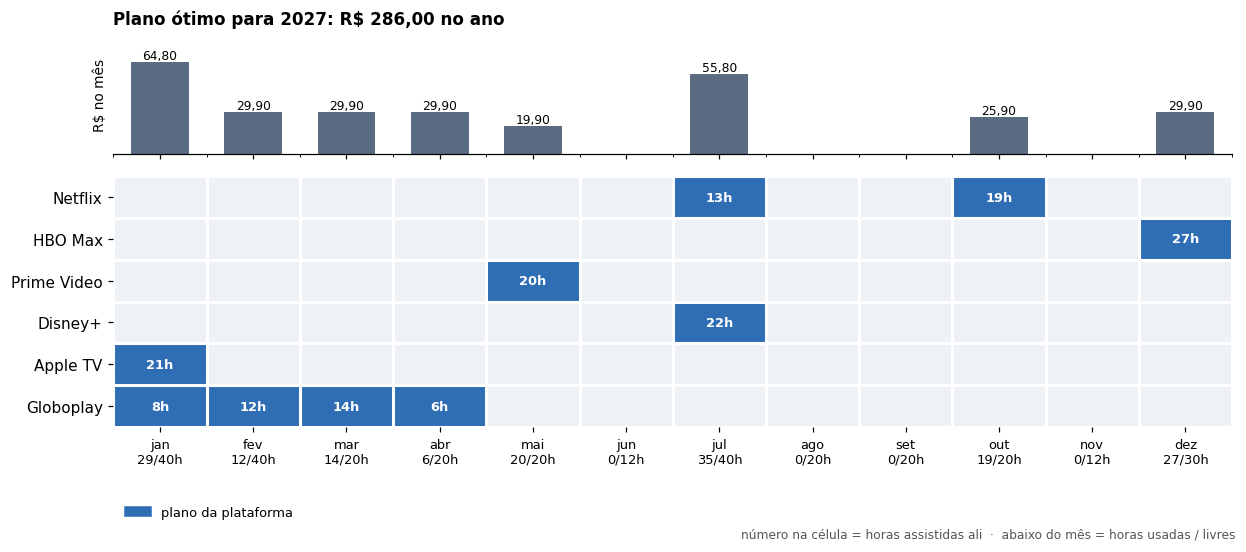

In [10]:
plano = otimizar(lista, ofertas, HORAS_LIVRES)

print(f"Status: {plano.status}  |  custo no ano: {brl(plano.custo)}  |  tempo: {plano.tempo:.1f} s")
print(f"Tamanho do modelo: {plano.tamanho['binárias']} variáveis binárias e {plano.tamanho['restrições']} restrições")
print("Conferência independente:", verificar(plano) or "OK, o plano respeita todas as regras")
display(tabela_plano(plano))
calendario(plano, "Plano ótimo para 2027")

In [11]:
# Leitura do plano, gerada a partir do resultado (vale para qualquer dado de entrada)
d = plano.dados
meses_pagos = [m for j, m in enumerate(d["meses"]) if gasto_mensal(plano)[j] > 0]
vezes = {}
for o in plano.y.index:
    for m in d["meses"]:
        if plano.y.at[o, m] > 0.5:
            for pl in ofertas.set_index("oferta").at[o, "plataformas"]:
                vezes[pl] = vezes.get(pl, 0) + 1
print(f"• Pago assinatura em {len(meses_pagos)} dos 12 meses; nos outros "
      f"({', '.join(NOMES_MESES[m - 1] for m in d['meses'] if m not in meses_pagos)}) não pago nada.")
print("• Meses de acesso a cada plataforma: " + ", ".join(f"{pl} {n}×" for pl, n in vezes.items()))
print(f"• Custo médio: {brl(plano.custo / 12)} por mês, ou {brl(plano.custo / unicos['horas'].sum())} por hora assistida.")
usa_combo = any(plano.y.at[o, m] > 0.5 for o in plano.y.index if "Meli+" in o for m in d["meses"])
print(f"• O combo Meli+ Mega {'entrou' if usa_combo else 'não entrou'} no plano ótimo.")

• Pago assinatura em 8 dos 12 meses; nos outros (jun, ago, set, nov) não pago nada.
• Meses de acesso a cada plataforma: Netflix 2×, HBO Max 1×, Prime Video 1×, Disney+ 1×, Apple TV 1×, Globoplay 4×
• Custo médio: R$ 23,83 por mês, ou R$ 1,77 por hora assistida.
• O combo Meli+ Mega não entrou no plano ótimo.


**Como ler o plano.** O padrão que aparece é o de **maratonar uma ou duas plataformas por mês, nos meses com mais tempo livre**, e não pagar nada nos meses apertados (provas). Três forças moldam a solução:
- os **programas ao vivo e os lançamentos** fixam alguns meses (o BBB prende o Globoplay de janeiro a abril, e o modelo aproveita esses meses para encaixar o resto do Globoplay);
- as **horas livres** decidem quando uma plataforma cabe num mês só ou precisa voltar uma segunda vez;
- o **preço** decide quais plataformas dividem o mesmo mês e se vale a pena um combo.

### 3.6 Quanto economizamos? Comparação com estratégias simples
Comparamos o plano ótimo com:
1. **Assinar tudo o ano inteiro:** todo mês, a combinação mais barata de ofertas que dá acesso às 6 plataformas (é o que se faz sem rodízio);
2. **Assistir o quanto antes, sem planejar:** cada título vai para o primeiro mês em que está disponível e ainda cabe nas horas livres (os programas ao vivo primeiro); depois, em cada mês, paga-se a combinação mais barata de ofertas que dá acesso ao que foi visto;
3. **Ótimo sem anúncios:** o mesmo modelo, só com ofertas sem anúncios.

'Assinar tudo' usa, todo mês: Amazon Prime (Prime Video c/ anúncios) + Globoplay Padrão c/ anúncios + Meli+ Mega c/ anúncios


,custo no ano,economia em relação a assinar tudo
estratégia,,
Assinar tudo o ano inteiro,"R$ 1.496,40",0%
"Assistir o quanto antes, sem planejar","R$ 500,30",67%
Ótimo sem anúncios,"R$ 423,00",72%
Ótimo (modelo),"R$ 286,00",81%


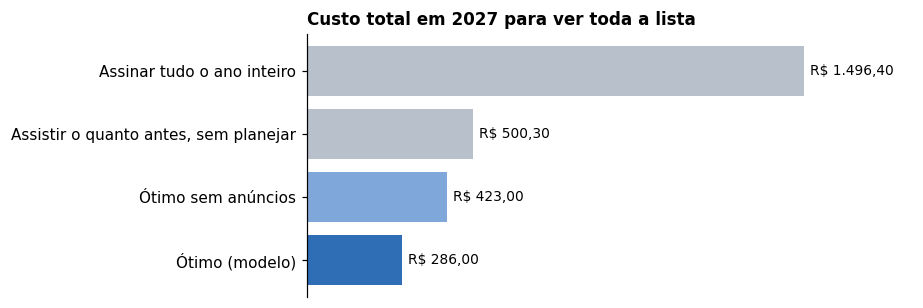

Não ver anúncios custa R$ 137,00 a mais no ano, ou R$ 0,85 por hora assistida: esse é o 'preço do conforto'.


In [12]:
def estrategia_assinar_tudo(lista, ofertas, horas):
    plataformas = F(lista["plataforma"])
    custo_mes, escolha = cobertura_mais_barata(ofertas)(F(F({p}) for p in plataformas))
    return custo_mes * len(horas), escolha


def estrategia_o_quanto_antes(lista, ofertas, horas):
    d = processar_entrada(lista, horas)
    cobrir = cobertura_mais_barata(ofertas)
    livre = dict(d["H"]["Eu"])
    exigencias = {m: set() for m in d["meses"]}
    # primeiro quem tem prazo (ao vivo, saindo do catálogo); depois na ordem da estreia
    ordem = sorted(d["unidades"], key=lambda u: (max(m for m in d["meses"] if d["info"][u]["A"][m]),
                                                 d["info"][u]["estreia"]))
    for u in ordem:
        i = d["info"][u]
        mes = next((m for m in d["meses"] if i["A"][m] and livre[m] >= i["horas"] - 1e-9), None)
        if mes is None:
            return None
        livre[mes] -= i["horas"]
        exigencias[mes].add(i["A"][mes])
    return sum(cobrir(F(e))[0] for e in exigencias.values())


custo_tudo, combinacao_tudo = estrategia_assinar_tudo(lista, ofertas, HORAS_LIVRES)
custo_antes = estrategia_o_quanto_antes(lista, ofertas, HORAS_LIVRES)
plano_sem_anuncios = otimizar(lista, ofertas[~ofertas["anuncios"]], HORAS_LIVRES)

comparacao = pd.DataFrame({
    "estratégia": ["Assinar tudo o ano inteiro", "Assistir o quanto antes, sem planejar",
                   "Ótimo sem anúncios", "Ótimo (modelo)"],
    "custo no ano": [custo_tudo, custo_antes, plano_sem_anuncios.custo, plano.custo],
})
comparacao["economia em relação a assinar tudo"] = (1 - comparacao["custo no ano"] / custo_tudo).map("{:.0%}".format)
print("'Assinar tudo' usa, todo mês:", " + ".join(combinacao_tudo))
display(comparacao.assign(**{"custo no ano": comparacao["custo no ano"].map(brl)}).set_index("estratégia"))

fig, ax = plt.subplots(figsize=(8.5, 2.9))
cores = ["#b8c0cc", "#b8c0cc", "#7fa7d9", "#2f6db5"]
barras = ax.barh(comparacao["estratégia"][::-1], comparacao["custo no ano"][::-1], color=cores[::-1])
ax.bar_label(barras, labels=[brl(v) for v in comparacao["custo no ano"][::-1]], padding=4, fontsize=9)
ax.set_xlim(0, custo_tudo * 1.22); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Custo total em 2027 para ver toda a lista", loc="left")
plt.tight_layout(); plt.show()

extra = plano_sem_anuncios.custo - plano.custo
print(f"Não ver anúncios custa {brl(extra)} a mais no ano, ou {brl(extra / unicos['horas'].sum())} "
      f"por hora assistida: esse é o 'preço do conforto'.")

Duas lições:
- **A maior economia vem do rodízio em si**, ou seja, de não pagar plataformas nos meses em que não vou usá-las.
- **Planejar faz diferença mesmo para quem já faz rodízio.** A estratégia "o quanto antes" espalha as plataformas por muitos meses e paga várias mensalidades a mais. O modelo concentra o que é de cada plataforma nos mesmos meses e escolhe quais plataformas dividem o mês.

## 4. Entendendo a solução

### 4.1 Por que variáveis inteiras? A relaxação linear
Se deixássemos as variáveis assumirem valores fracionários entre 0 e 1, o solver poderia "assinar 40% da Netflix em março" e pagar 40% do preço. O ótimo desse problema relaxado é um **limite inferior** para o ótimo inteiro, e a diferença entre os dois é o **gap de integralidade** (aula 18). É ela que obriga o solver a fazer *branch-and-bound*: dividir o problema em ramos ($y=0$ ou $y=1$) até provar que nenhum plano é mais barato.

In [13]:
relaxado = otimizar(lista, ofertas, HORAS_LIVRES, relaxar=True)
print(f"Relaxação linear (limite inferior): {brl(relaxado.custo)}")
print(f"Ótimo inteiro:                      {brl(plano.custo)}")
print(f"Gap de integralidade:               {(plano.custo - relaxado.custo) / plano.custo:.1%}")

fracoes = (relaxado.y.stack().loc[lambda s: (s > 1e-6) & (s < 1 - 1e-6)]
           .sort_values(ascending=False).head(8))
print("\nAlgumas 'assinaturas fracionárias' da relaxação (impossíveis na vida real):")
for (oferta, m), v in fracoes.items():
    print(f"   {v:5.0%} de '{oferta}' em {NOMES_MESES[m - 1]}")

Relaxação linear (limite inferior): R$ 229,39
Ótimo inteiro:                      R$ 286,00
Gap de integralidade:               19.8%

Algumas 'assinaturas fracionárias' da relaxação (impossíveis na vida real):
     44% de 'Netflix Padrão c/ anúncios' em nov
     41% de 'Meli+ Mega c/ anúncios' em jul
     30% de 'Meli+ Mega c/ anúncios' em dez
     25% de 'Meli+ Mega c/ anúncios' em out
      6% de 'HBO Max Básico c/ anúncios' em fev
      3% de 'Meli+ Mega c/ anúncios' em fev
      2% de 'Meli+ Mega c/ anúncios' em set
      2% de 'Disney+ Padrão c/ anúncios' em set


### 4.2 Uma formulação mais forte: o menor $M$ e um corte de Chvátal–Gomory
Duas formulações podem ter **as mesmas soluções inteiras** e relaxações lineares muito diferentes. Quanto mais justa a relaxação, mais cedo o *branch-and-bound* descarta ramos (aulas 19 e 23). Por isso o modelo tem dois ingredientes extras.

**(a) A restrição (4), um big-M com o menor $M$ possível.** Na relaxação, a restrição (3) só exige $y_{k,m}\ge x_{t,m}$ para cada título **separadamente**: com $y=0{,}5$ dá para ver metade de *cada* título da plataforma naquele mês, por mais horas que isso some. A restrição (4) amarra as **horas** ao acesso: com $M=H_m$, que é o menor valor que não corta nenhum plano válido, as horas vistas em títulos exclusivos da plataforma $p$ ficam limitadas a $H_m$ vezes o acesso a $p$. Na relaxação, cada hora assistida passa a "pagar" a sua fração da mensalidade.

**(b) Cortes de Chvátal–Gomory.** Seja $h_p$ o total de horas dos títulos que só existem em $p$, e $H_{\max}=\max_m H_m$. Somando (4) em todos os meses:
$$h_p \;=\; \sum_{m}\sum_{t} h_t\,x_{t,m} \;\le\; \sum_{m} H_m \sum_{k:\,p\in P_k} y_{k,m} \;\le\; H_{\max}\sum_{m}\sum_{k:\,p\in P_k} y_{k,m}.$$
Dividindo por $H_{\max}$, e como o lado direito é um **número inteiro** de meses, podemos arredondar para cima:
$$\sum_{m\in M}\ \sum_{k:\,p\in P_k} y_{k,m} \;\ge\; \left\lceil \frac{h_p}{H_{\max}} \right\rceil. \qquad (5)$$
Isso é exatamente um corte de Chvátal–Gomory [Gomory, 1958; Chvátal, 1973]: combina restrições válidas, arredonda e obtém uma desigualdade que **nenhum plano inteiro viola**, mas que corta soluções fracionárias. Em palavras: "se a Netflix tem 32 h exclusivas e eu vejo no máximo 20 h por mês, ela precisa estar ativa em pelo menos 2 meses".

**Experimento.** Com as horas livres da seção 3.4, tudo resolve em poucos segundos. Para ver a diferença, usamos uma versão mais apertada: **20 horas em todos os meses**. Rodamos as quatro combinações (com limite de 30 s cada; esta célula leva cerca de 1 minuto).

In [14]:
H_APERTADO = {m: 20 for m in HORAS_LIVRES}
linhas = []
for nome, forte, cortes in [("(1)–(3): formulação básica",        False, False),
                            ("básica + restrição forte (4)",       True,  False),
                            ("básica + cortes (5)",                False, True),
                            ("básica + (4) + (5)  [a do notebook]", True,  True)]:
    lp = otimizar(lista, ofertas, H_APERTADO, forte=forte, cortes=cortes, relaxar=True)
    ip = otimizar(lista, ofertas, H_APERTADO, forte=forte, cortes=cortes, limite_tempo=30)
    gap = (ip.custo - ip.limite_inferior) / ip.custo
    linhas.append({"formulação": nome,
                   "limite da relaxação linear": brl(lp.custo),
                   "melhor plano achado": brl(ip.custo),
                   "provou o ótimo?": "sim" if ip.otimo else f"não em 30 s (gap {gap:.0%})",
                   "tempo (s)": round(ip.tempo, 1)})
display(pd.DataFrame(linhas).set_index("formulação"))

,limite da relaxação linear,melhor plano achado,provou o ótimo?,tempo (s)
formulação,,,,
(1)–(3): formulação básica,"R$ 225,61","R$ 360,90",não em 30 s (gap 13%),30.0
básica + restrição forte (4),"R$ 242,32","R$ 360,90",sim,18.4
básica + cortes (5),"R$ 289,30","R$ 360,90",sim,11.3
básica + (4) + (5) [a do notebook],"R$ 289,30","R$ 360,90",sim,12.9


**O que a tabela mostra:** as quatro formulações têm as **mesmas soluções inteiras**, e por isso acham o mesmo plano quando terminam. Mas a relaxação linear da básica é bem mais frouxa, o que a deixa lenta. A restrição (4) e os cortes (5) aproximam o limite inferior do ótimo, e o *branch-and-bound* passa a provar o ótimo muito mais rápido. É a lição das aulas 19 e 23 na prática: **em programação inteira, como se escreve o modelo importa tanto quanto o que ele diz.** (Os tempos variam de computador para computador; a ordem entre as formulações, não.)

## 5. Discussão

### 5.1 Quanto vale o meu tempo livre? (e: e se eu puder dividir um título entre meses?)
Multiplicamos todas as horas livres por um fator (de 0,6× a 2×) e resolvemos de novo. Também testamos a variação em que **um título pode ser dividido entre meses**: basta trocar $x_{t,m}\in\{0,1\}$ por $x_{t,m}\in[0,1]$ (a fração do título vista no mês $m$); os $y$ continuam binários. Se algum ponto aparecer vazado, ele não foi provado ótimo dentro do limite de 30 s (o valor mostrado é o melhor plano encontrado). Esta célula leva cerca de 1 minuto.

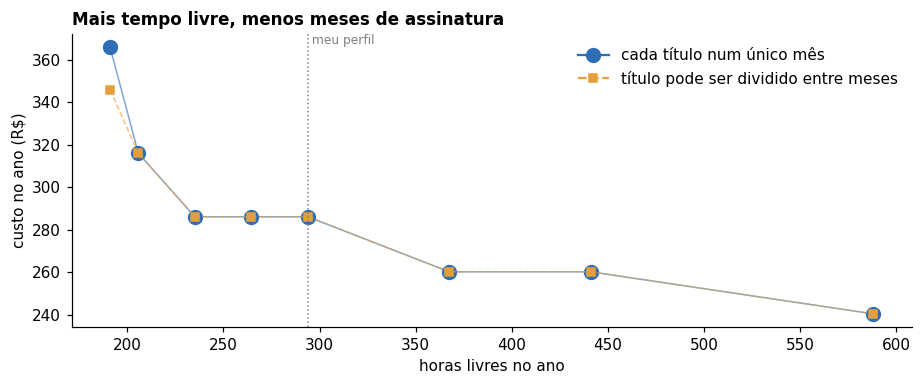

,horas livres no ano,título inteiro,título dividido
fator,,,
0.65,191,"R$ 365,70","R$ 345,80"
0.70,206,"R$ 315,90","R$ 315,90"
0.80,235,"R$ 286,00","R$ 286,00"
0.90,265,"R$ 286,00","R$ 286,00"
1.00,294,"R$ 286,00","R$ 286,00"
1.25,368,"R$ 260,10","R$ 260,10"
1.50,441,"R$ 260,10","R$ 260,10"
2.00,588,"R$ 240,30","R$ 240,30"


In [15]:
fatores = [0.65, 0.7, 0.8, 0.9, 1.0, 1.25, 1.5, 2.0]
sens = []
for a in fatores:
    perfil = {m: h * a for m, h in HORAS_LIVRES.items()}
    inteiro = otimizar(lista, ofertas, perfil, limite_tempo=30)
    partes = otimizar(lista, ofertas, perfil, dividir=True, limite_tempo=30)
    sens.append({"fator": a, "horas livres no ano": sum(perfil.values()),
                 "inteiro": inteiro, "partes": partes})

fig, ax = plt.subplots(figsize=(8.5, 3.6))
for chave, cor, marca, tam, rotulo in [("inteiro", "#2f6db5", "o", 9, "cada título num único mês"),
                                       ("partes", "#e59f3a", "s", 5, "título pode ser dividido entre meses")]:
    pts = [(s["horas livres no ano"], s[chave]) for s in sens if s[chave] is not None]
    ax.plot([p[0] for p in pts], [p[1].custo for p in pts], color=cor, lw=1, alpha=0.6,
            ls="-" if chave == "inteiro" else "--")
    for hx, pl in pts:
        ax.plot(hx, pl.custo, marca, color=cor, mfc=cor if pl.otimo else "white", ms=tam)
    ax.plot([], [], marca, color=cor, ms=tam, ls="-" if chave == "inteiro" else "--", label=rotulo)
ax.axvline(sum(HORAS_LIVRES.values()), color="gray", ls=":", lw=1)
ax.text(sum(HORAS_LIVRES.values()), ax.get_ylim()[1], " meu perfil", va="top", fontsize=8, color="gray")
ax.set_xlabel("horas livres no ano"); ax.set_ylabel("custo no ano (R$)")
ax.set_title("Mais tempo livre, menos meses de assinatura", loc="left"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

display(pd.DataFrame([{"fator": s["fator"], "horas livres no ano": round(s["horas livres no ano"]),
                       "título inteiro": brl(s["inteiro"].custo) + ("" if s["inteiro"].otimo else " (não provado)") if s["inteiro"] else "inviável",
                       "título dividido": brl(s["partes"].custo) + ("" if s["partes"].otimo else " (não provado)") if s["partes"] else "inviável"}
                      for s in sens]).set_index("fator"))

**Leitura.** O custo cai em **degraus**: cada degrau acontece quando sobra tempo para encaixar uma plataforma inteira num mês só, ou seja, um corte do tipo (5) deixa de exigir um mês a mais. Com pouco tempo, o custo sobe depressa, e **dividir títulos entre meses ajuda justamente aí**: o título deixa de "não caber" e passa a ocupar o espaço que sobra nos meses já pagos. Com tempo de sobra, as duas versões coincidem.

### 5.2 Quanto custa fugir de spoiler?
O plano ótimo da seção 3.5 não tem pressa nenhuma: se for mais barato, ele deixa um lançamento para muitos meses depois da estreia (veja a última linha da tabela abaixo). Para quem quer evitar spoilers, impomos uma **espera máxima de $D$ meses** para os títulos marcados `sem_spoiler`. No modelo, isso só encurta a janela: $M_t=\{a_t,\dots,a_t+D\}$, em que $a_t$ é o mês da estreia. Variar $D$ dá uma **curva de compromisso entre custo e espera**, como nas curvas de Pareto da aula 9.

,custo no ano,Dungeon Meshi T2,Harry Potter T1,Vingadores: Doutor Destino
espera máxima (meses),,,,
0,"R$ 315,90",out (+0),fev (+0),abr (+0)
1,"R$ 300,10",out (+0),fev (+0),mai (+1)
2,"R$ 300,10",dez (+2),fev (+0),abr (+0)
3,"R$ 286,00",dez (+2),fev (+0),jul (+3)
4,"R$ 286,00",out (+0),fev (+0),jul (+3)
6,"R$ 286,00",nov (+1),fev (+0),jul (+3)
12,"R$ 286,00",out (+0),dez (+10),jul (+3)


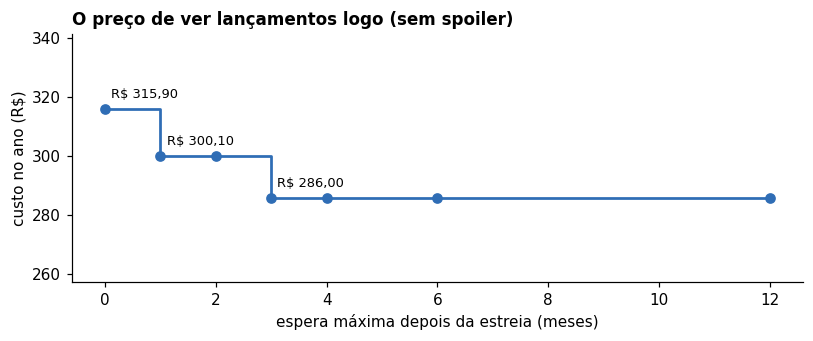

Ver tudo no mês da estreia custa R$ 29,90 a mais no ano do que não ter pressa nenhuma.


In [16]:
esperas = [0, 1, 2, 3, 4, 6, 12]
titulos_spoiler = list(lista.loc[lista["sem_spoiler"], "titulo"].unique())
linhas, custos_espera = [], []
for D in esperas:
    p = otimizar(lista, ofertas, HORAS_LIVRES, espera_max=D)
    custos_espera.append(p.custo)
    linha = {"espera máxima (meses)": D, "custo no ano": brl(p.custo)}
    for t in titulos_spoiler:
        m = max(p.x[(t, "Eu")], key=p.x[(t, "Eu")].get)
        linha[t] = f"{NOMES_MESES[m - 1]} (+{m - p.dados['info'][(t, 'Eu')]['estreia']})"
    linhas.append(linha)
display(pd.DataFrame(linhas).set_index("espera máxima (meses)"))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.step(esperas, custos_espera, where="post", color="#2f6db5", lw=1.8)
ax.plot(esperas, custos_espera, "o", color="#2f6db5")
for i, (D, c) in enumerate(zip(esperas, custos_espera)):
    if i == 0 or abs(c - custos_espera[i - 1]) > 1e-6:          # rótulo só onde o custo muda
        ax.annotate(brl(c), (D, c), textcoords="offset points", xytext=(4, 7), ha="left", fontsize=8.5)
ax.set_xlabel("espera máxima depois da estreia (meses)"); ax.set_ylabel("custo no ano (R$)")
ax.set_ylim(min(custos_espera) * 0.9, max(custos_espera) * 1.08)
ax.set_title("O preço de ver lançamentos logo (sem spoiler)", loc="left")
plt.tight_layout(); plt.show()
print(f"Ver tudo no mês da estreia custa {brl(custos_espera[0] - custos_espera[-1])} a mais no ano "
      f"do que não ter pressa nenhuma.")

(Entre parênteses na tabela: quantos meses depois da estreia cada lançamento é visto.) A curva é uma **fronteira de compromisso**: abaixo dela não há plano possível. A forma de "escada" é típica de problemas inteiros, e uma alternativa seria a **soma ponderada** da aula 9, minimizando custo $+\ \lambda\cdot$(meses de espera) para vários $\lambda$. Com variáveis inteiras, porém, a soma ponderada só encontra os pontos da fronteira que estão na sua envoltória convexa (os pontos "suportados"), enquanto restringir a espera, como fizemos (o método da restrição $\varepsilon$), encontra todos.

### 5.3 Vale a pena o plano anual?
Os planos anuais são a principal arma das plataformas contra o rodízio: são mais baratos que 12 mensalidades, mas só se você ficar o ano inteiro. Incluímos no modelo as ofertas anuais com variáveis binárias $z_j$, que custam o preço anual e dão acesso nos 12 meses: na restrição (3), $x_{t,m}\le\sum_k y_{k,m}+\sum_j z_j$ para as ofertas que dão acesso a $t$.

In [17]:
ofertas_anuais = pd.DataFrame([
    # oferta anual,                         dá acesso a,           R$/ano,  plano mensal comparável
    ("Amazon Prime anual",                   F({"Prime Video"}),   166.80, "Amazon Prime (Prime Video c/ anúncios)"),
    ("HBO Max Básico c/ anúncios anual",     F({"HBO Max"}),       274.80, "HBO Max Básico c/ anúncios"),
    ("Disney+ Padrão anual",                 F({"Disney+"}),       407.88, "Disney+ Padrão"),
    ("Apple TV anual",                       F({"Apple TV"}),      279.00, "Apple TV"),
], columns=["oferta", "plataformas", "preco", "mensal_equivalente"])

precos_mensais = ofertas.set_index("oferta")["preco"]
meses_no_plano = {pl: sum(1 for m in plano.dados["meses"]
                          if any(plano.y.at[o, m] > 0.5 and pl in ofertas.set_index("oferta").at[o, "plataformas"]
                                 for o in plano.y.index))
                  for pl in plano.dados["plataformas"]}
tabela_anual = pd.DataFrame([{
    "plano anual": r.oferta, "preço anual": brl(r.preco),
    "equivale a quantas mensalidades": f"{r.preco / precos_mensais[r.mensal_equivalente]:.1f}",
    "meses que o plano ótimo usa essa plataforma": meses_no_plano[next(iter(r.plataformas))],
} for r in ofertas_anuais.itertuples()]).set_index("plano anual")
display(tabela_anual)

plano_anual = otimizar(lista, ofertas, HORAS_LIVRES, ofertas_anuais=ofertas_anuais)
print(f"Com a opção de planos anuais, o custo ótimo é {brl(plano_anual.custo)} "
      f"(antes: {brl(plano.custo)}). Planos anuais escolhidos: {plano_anual.anuais or 'nenhum'}.")

,preço anual,equivale a quantas mensalidades,meses que o plano ótimo usa essa plataforma
plano anual,,,
Amazon Prime anual,"R$ 166,80",8.4,1
HBO Max Básico c/ anúncios anual,"R$ 274,80",9.2,1
Disney+ Padrão anual,"R$ 407,88",8.2,1
Apple TV anual,"R$ 279,00",8.0,1


Com a opção de planos anuais, o custo ótimo é R$ 286,00 (antes: R$ 286,00). Planos anuais escolhidos: nenhum.


Um plano anual custa o mesmo que 8 a 9 mensalidades do plano mensal equivalente (tabela acima), então só compensa para quem usaria a plataforma por uns 9 meses ou mais no ano. Com rodízio, cada plataforma é usada só 1 ou 2 meses (o Globoplay, 4, por causa do BBB), então **nenhum plano anual entra**. É por isso que as plataformas oferecem desconto no anual: ele só atrai quem não faria rodízio.

(Dados dos planos anuais: Notícias de Perto, 25/09/2026, e ANTI/HYPE, 09/11/2026. O Globoplay ficou de fora porque o preço anual publicado é anterior ao reajuste de outubro de 2026.)

### 5.4 Dividindo as assinaturas com a república
Agora três moradores da mesma casa dividem as assinaturas. Isso é permitido nos planos comuns, porque é a mesma residência; mas os planos com anúncios costumam liberar só duas telas ao mesmo tempo. Cada morador tem a sua lista e as suas horas livres; a Bia trabalha e estuda, e tem **metade** do meu tempo livre. No modelo, os títulos ganham um "dono", a restrição (2) passa a valer **por pessoa e por mês**, e as assinaturas $y$ são compartilhadas: uma mensalidade dá acesso a todos.

Eu                  R$ 286,00
Bia                 R$ 235,20
Caio                R$ 120,70
Eu + Bia            R$ 300,10
Eu + Caio           R$ 286,00
Bia + Caio          R$ 296,10
Eu + Bia + Caio     R$ 300,10

Conferência do plano do grupo: OK
Cada um sozinho: R$ 641,90 no total  |  juntos: R$ 300,10  (economia de 53%)


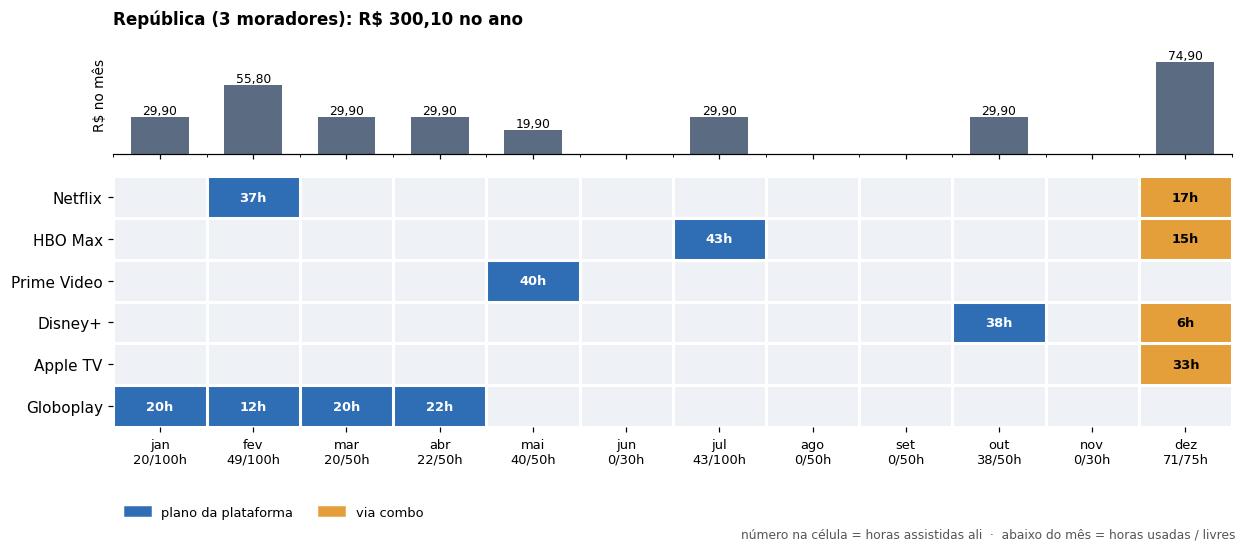

In [18]:
listas = {
    "Eu":   list(unicos["titulo"]),                    # a minha lista completa (seção 3.4)
    "Bia":  ["Harry Potter T1", "A Casa do Dragão T3", "The Last of Us T2", "Wandinha T2",
             "Stranger Things 5", "BBB 27 (jan)", "BBB 27 (fev)", "BBB 27 (mar)", "BBB 27 (abr)",
             "Sessão de Terapia T6", "O Urso T4", "Ainda Estou Aqui"],
    "Caio": ["Vingadores: Doutor Destino", "Avatar: Fogo e Cinzas", "Shōgun T1", "The Boys T5",
             "Fallout T2", "Pluribus", "O Estúdio", "Dungeon Meshi T2", "Tremembé", "Harry Potter T1"],
}
tempo_livre = {"Eu": 1.0, "Bia": 0.5, "Caio": 1.0}       # fração das minhas horas livres


def lista_do_grupo(grupo):
    return pd.concat([lista[lista["titulo"].isin(listas[p])].assign(quem=p) for p in grupo], ignore_index=True)


def horas_do_grupo(grupo):
    return {p: {m: h * tempo_livre[p] for m, h in HORAS_LIVRES.items()} for p in grupo}


moradores = tuple(listas)
custo_grupo, planos_grupo = {}, {}
for r in range(1, len(moradores) + 1):
    for S in itertools.combinations(moradores, r):
        planos_grupo[S] = otimizar(lista_do_grupo(S), ofertas, horas_do_grupo(S))
        custo_grupo[S] = planos_grupo[S].custo

for S, c in custo_grupo.items():
    print(f"{' + '.join(S):<16} {brl(c):>12}")
juntos = planos_grupo[moradores]
print("\nConferência do plano do grupo:", verificar(juntos) or "OK")
soma_sozinhos = sum(custo_grupo[(p,)] for p in moradores)
print(f"Cada um sozinho: {brl(soma_sozinhos)} no total  |  juntos: {brl(juntos.custo)}  "
      f"(economia de {1 - juntos.custo / soma_sozinhos:.0%})")
calendario(juntos, "República (3 moradores)")

**Juntar nunca piora:** os planos individuais, somados, continuam sendo um plano viável para o grupo, então o ótimo do grupo é no máximo a soma dos ótimos individuais (o custo é **subaditivo**). A pergunta interessante é **como dividir a conta**. Quatro regras:
- **igual:** cada um paga um terço;
- **proporcional às horas** que cada um assiste;
- **valor de Shapley** [Shapley, 1953]: cada morador paga, em média, o **custo extra que ele causa** ao entrar na república, considerando todas as ordens de chegada possíveis;
- **a divisão que maximiza a menor economia** de qualquer subgrupo. É um PL com objetivo **minimax** (aula 4):
$$\max_{\varphi,\ \varepsilon}\ \varepsilon \quad\text{s.a.}\quad \sum_{i\in S}\varphi_i \le C(S)-\varepsilon\ \ \ \forall\, \emptyset\neq S\subsetneq N,\qquad \sum_{i\in N}\varphi_i=C(N),$$
em que $C(S)$ é o custo ótimo do subgrupo $S$ (os 7 MILPs acima) e $\varphi_i$ é quanto o morador $i$ paga.

Se o ótimo $\varepsilon^*$ for $\ge 0$, existe uma divisão em que **nenhum subgrupo ganharia saindo da república para assinar sozinho**. O conjunto dessas divisões é o **núcleo** (*core*) do jogo [Gillies, 1959], e a solução desse PL é o chamado *least core* [Maschler, Peleg & Shapley, 1979].

In [19]:
N = moradores
n = len(N)
chave = lambda S: tuple(sorted(S, key=N.index))

# Valor de Shapley: média do custo extra de cada morador em todas as ordens de chegada
shapley = {i: 0.0 for i in N}
for ordem in itertools.permutations(N):
    ja = ()
    for i in ordem:
        shapley[i] += (custo_grupo[chave(ja + (i,))] - (custo_grupo[chave(ja)] if ja else 0.0)) / math.factorial(n)
        ja = ja + (i,)

# PL "maximiza a menor economia" (variáveis: phi_1..phi_n, eps); linprog minimiza, então usamos -eps
subgrupos = [S for S in custo_grupo if len(S) < n]
res = linprog(c=[0.0] * n + [-1.0],
              A_ub=[[1.0 if i in S else 0.0 for i in N] + [1.0] for S in subgrupos],
              b_ub=[custo_grupo[S] for S in subgrupos],
              A_eq=[[1.0] * n + [0.0]], b_eq=[custo_grupo[N]],
              bounds=[(None, None)] * (n + 1), method="highs")
eps, phi_lp = res.x[-1], dict(zip(N, res.x[:n]))

horas_de = {p: unicos.set_index("titulo").loc[listas[p], "horas"].sum() for p in N}
regras = {
    "igual": {i: custo_grupo[N] / n for i in N},
    "proporcional às horas": {i: custo_grupo[N] * horas_de[i] / sum(horas_de.values()) for i in N},
    "Shapley": shapley,
    "PL minimax (least core)": phi_lp,
}
tabela = pd.DataFrame({"sozinho": {i: custo_grupo[(i,)] for i in N}, **regras})
display(tabela.map(brl))

def no_nucleo(phi):
    return all(sum(phi[i] for i in S) <= custo_grupo[S] + 1e-6 for S in subgrupos)

print(f"Menor economia garantida pelo PL: ε* = {brl(eps)} "
      f"→ {'o núcleo NÃO é vazio: existe divisão estável' if eps >= -1e-9 else 'núcleo vazio: nenhuma divisão é estável'}")
for nome, phi in regras.items():
    print(f"   divisão '{nome}': {'estável (está no núcleo)' if no_nucleo(phi) else 'algum subgrupo ganharia saindo'}")

,sozinho,igual,proporcional às horas,Shapley,PL minimax (least core)
Eu,"R$ 286,00","R$ 100,03","R$ 160,45","R$ 135,03","R$ 165,30"
Bia,"R$ 235,20","R$ 100,03","R$ 79,23","R$ 114,68","R$ 74,45"
Caio,"R$ 120,70","R$ 100,03","R$ 60,42","R$ 50,38","R$ 60,35"


Menor economia garantida pelo PL: ε* = R$ 60,35 → o núcleo NÃO é vazio: existe divisão estável
   divisão 'igual': estável (está no núcleo)
   divisão 'proporcional às horas': estável (está no núcleo)
   divisão 'Shapley': estável (está no núcleo)
   divisão 'PL minimax (least core)': estável (está no núcleo)


**Leitura.** Quem tem **menos tempo livre** (a Bia) obriga o grupo a manter algumas plataformas por mais meses, então o Shapley cobra mais dela do que do Caio, cuja lista "cabe" nos meses que eu já pago. A divisão igual é a mais simples, mas ignora isso. Em todos os casos, morar junto sai bem mais barato do que assinar sozinho.

### 5.5 Limitações
- **Dados.** Preços mudam (vários mudaram em 2026), datas de lançamento atrasam e catálogos mudam sem aviso. O modelo é tão bom quanto os dados; por isso as estimativas estão marcadas.
- **Horas livres** são uma estimativa grosseira, e o tempo real varia semana a semana.
- **Mês fechado:** na prática, a cobrança acontece no dia em que você assinou, e não no dia 1º. Uma versão por quinzena ou por semana resolveria isso, com mais variáveis.
- **Lançamento semanal:** assumimos que só começo a ver quando a temporada está completa. Quem acompanha semanalmente (como no caso de *Harry Potter*) precisa ficar assinado durante toda a exibição, o que é mais caro, e é exatamente o que as plataformas querem.
- **Anúncios:** tratamos o plano com anúncios como equivalente ao sem anúncios, só mais barato; o "incômodo" foi medido à parte (seção 3.6).
- **Valor de cada título:** o modelo exige ver **toda** a lista. Ele não decide se vale a pena deixar um título de fora para economizar uma mensalidade.

### 5.6 Generalizações e extensões
1. **Lista com prioridades:** em vez de exigir tudo, maximizar o "valor" do que assisto com um orçamento fixo, o que vira um problema da mochila com custo fixo.
2. **Ordem entre temporadas:** "ver a T1 antes da T2" vira uma restrição de precedência: $\sum_{m'\le m} x_{T1,m'} \ge \sum_{m'\le m} x_{T2,m'}$.
3. **Semanal × maratona:** cada título com dois "modos" de consumo (acompanhar semanalmente ou maratonar depois) e uma variável binária para escolher o modo, usando as restrições lógicas da aula 20.
4. **Incerteza:** datas de estreia e preços incertos levam à otimização robusta (aula 13) ou estocástica, com cenários.
5. **Preços que mudam ao longo do ano** (promoções, Black Friday): basta trocar $c_k$ por $c_{k,m}$; o modelo continua igual.
6. **Mercado em movimento:** a compra da Warner Bros. (dona da HBO Max) pela Netflix, anunciada em dezembro de 2025 [PBS NewsHour, 2025], pode criar um combo Netflix + HBO Max. No modelo, ele é só mais uma linha na tabela de ofertas.

### 5.7 Conclusão
Um problema do dia a dia virou um MILP pequeno que junta **cobertura de conjuntos**, **custo fixo** e **planejamento com capacidade**. O modelo foi conferido por força bruta no exemplo pequeno e por um verificador independente na instância real. Ele mostrou que:
- o rodízio planejado custa uma fração de assinar tudo;
- **como** se escreve o modelo (big-M justo e cortes) muda muito o tempo de solução;
- dá para medir de forma objetiva o preço do conforto (anúncios), da pressa (spoilers) e do tempo livre, e dividir a conta da república de forma justa.

In [20]:
print("RESUMO DOS RESULTADOS (gerado pelo notebook)")
print(f"  Plano ótimo para 2027 ..................... {brl(plano.custo)}  ({plano.status}, {plano.tempo:.1f} s)")
print(f"  Assinar tudo o ano inteiro ................ {brl(custo_tudo)}  (o ótimo economiza {1 - plano.custo / custo_tudo:.0%})")
print(f"  Assistir o quanto antes, sem planejar ..... {brl(custo_antes)}  (o ótimo economiza {1 - plano.custo / custo_antes:.0%})")
print(f"  Ótimo sem anúncios ........................ {brl(plano_sem_anuncios.custo)}")
print(f"  Limite da relaxação linear ................ {brl(relaxado.custo)}  (gap {(plano.custo - relaxado.custo) / plano.custo:.0%})")
print(f"  Ver lançamentos no mês da estreia ......... +{brl(custos_espera[0] - custos_espera[-1])} por ano")
print(f"  República (3 moradores) ................... {brl(juntos.custo)} juntos x {brl(soma_sozinhos)} separados")

RESUMO DOS RESULTADOS (gerado pelo notebook)
  Plano ótimo para 2027 ..................... R$ 286,00  (ótimo, 1.9 s)
  Assinar tudo o ano inteiro ................ R$ 1.496,40  (o ótimo economiza 81%)
  Assistir o quanto antes, sem planejar ..... R$ 500,30  (o ótimo economiza 43%)
  Ótimo sem anúncios ........................ R$ 423,00
  Limite da relaxação linear ................ R$ 229,39  (gap 20%)
  Ver lançamentos no mês da estreia ......... +R$ 29,90 por ano
  República (3 moradores) ................... R$ 300,10 juntos x R$ 641,90 separados


## Referências

**Pesquisa Operacional e otimização**
- Chvátal, V. (1973). Edmonds polytopes and a hierarchy of combinatorial problems. *Discrete Mathematics*, 4(4), 305–337.
- Chvátal, V. (1979). A greedy heuristic for the set-covering problem. *Mathematics of Operations Research*, 4(3), 233–235.
- Florian, M., Lenstra, J. K., & Rinnooy Kan, A. H. G. (1980). Deterministic production planning: algorithms and complexity. *Management Science*, 26(7), 669–679.
- Gillies, D. B. (1959). Solutions to general non-zero-sum games. In *Contributions to the Theory of Games IV* (Annals of Mathematics Studies 40), 47–85.
- Gomory, R. E. (1958). Outline of an algorithm for integer solutions to linear programs. *Bulletin of the American Mathematical Society*, 64(5), 275–278.
- Hirsch, W. M., & Dantzig, G. B. (1968). The fixed charge problem. *Naval Research Logistics Quarterly*, 15(3), 413–424.
- Hoffman, K. L., & Padberg, M. (1993). Solving airline crew scheduling problems by branch-and-cut. *Management Science*, 39(6), 657–682.
- Huangfu, Q., & Hall, J. A. J. (2018). Parallelizing the dual revised simplex method. *Mathematical Programming Computation*, 10(1), 119–142. (solver HiGHS)
- Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations*, 85–103. Plenum Press.
- Maschler, M., Peleg, B., & Shapley, L. S. (1979). Geometric properties of the kernel, nucleolus, and related solution concepts. *Mathematics of Operations Research*, 4(4), 303–338.
- Shapley, L. S. (1953). A value for n-person games. In *Contributions to the Theory of Games II* (Annals of Mathematics Studies 28), 307–317.
- Toregas, C., Swain, R., ReVelle, C., & Bergman, L. (1971). The location of emergency service facilities. *Operations Research*, 19(6), 1363–1373.
- Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.
- Wagner, H. M., & Whitin, T. M. (1958). Dynamic version of the economic lot size model. *Management Science*, 5(1), 89–96.
- Wolsey, L. A. (1998). *Integer Programming*. Wiley.
- Lessard, L. *CS/ECE/ISyE 524 – Introduction to Optimization* (notas de aula usadas na disciplina): aulas 4–5 (planejamento e fluxos), 9–10 (trade-offs), 18–21 (relaxação, custo fixo, restrições lógicas, cobertura de conjuntos) e 23 (planos de corte e *branch-and-bound*).

**Mercado e dados (consultados em 18/11/2026)**
- ANTI/HYPE (09/11/2026). *Preço dos streamings no Brasil soma R\$ 205 por mês nos planos mais baratos.* https://antihype.com.br/c/cultura-digital/preco-streamings-brasil-aumento-netflix-desde-estreia/
- Oficina da Net (20/10/2026). *Quanto custa assinar Netflix, HBO Max, Prime Video e todos os streamings em 2026?* https://www.oficinadanet.com.br/entretenimento/67623-quanto-custa-todos-streamings-brasil-2026
- Notícias de Perto (25/09/2026). *Quanto custa cada streaming no Brasil* (planos anuais). https://tvdeperto.com.br/streaming/quanto-custa-cada-streaming-brasil/
- Canaltech (21/05/2026). *Meli+: vale a pena assinar o plano do Mercado Livre em 2026?* https://canaltech.com.br/internet/meli-vale-a-pena-assinar-o-plano-do-mercado-livre-em-2026/
- Legião dos Heróis (2026). *Harry Potter: HBO revela primeiro pôster da série e confirma data de estreia.* https://www.legiaodosherois.com.br/2026/harry-potter-hbo-revela-primeiro-poster-da-serie-mostra-hogwarts-e-confirma-data-de-estreia.html
- Ingresso.com. *Vingadores: Doomsday – nova data de estreia.* https://www.ingresso.com/noticias/novos-filmes-vingadores-doomsday-guerras-secretas-nova-data-de-estreia
- GameOverdrive (19/10/2026). *Netflix fecha acordo com a Globo para 18 produções.* https://gameoverdrive.com.br/netflix-globo-acordo-18-producoes-filmes-novelas-series/
- Critical Hits. *Os 5 animes mais aguardados de 2027.* https://criticalhits.com.br/anime/os-5-animes-mais-aguardados-de-2027/
- Showmetech (2026). *Lançamentos do Globoplay em novembro de 2026.* https://www.showmetech.com.br/lancamentos-do-globoplay-em-novembro-de-2026/
- Oficina da Net (2026). *Globoplay: lançamentos de maio de 2026.* https://www.oficinadanet.com.br/entretenimento/69274-globoplay-lancamentos-maio-2026
- PBS NewsHour (12/2025). *Netflix to acquire Warner Bros. studio and streaming business for \$72 billion.* https://www.pbs.org/newshour/economy/netflix-to-acquire-warner-bros-studio-and-streaming-business-for-72-billion
- Deloitte Insights (2024). *Digital Media Trends.* (comportamento de *serial churners*)
- JustWatch Brasil (disponibilidade de títulos por plataforma). https://www.justwatch.com/br